In [2]:
%pip install pandas numpy scikit-learn matplotlib seaborn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 89.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 163.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 136.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [16]:
%pip install --force-reinstall "numpy==1.26.4" "scipy==1.13.1" "scikit-learn==1.5.2"

  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 126.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.2/38.2 MB 156.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 126.1 MB/s eta 0:00:00
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.8.0
    Uninstalling threadpoolctl-3.8.0:
      Successfully uninstalled threadpoolctl-3.8.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
  Attempting uninstall: scipy
    Found existing installation: scipy 1.18.1
    Uninstalling scipy-1.18.1:
      Successfully uninstalled scipy-1.18.1
  Attempting uninstall: joblib
    Found existing installation: joblib 1.4.2
    Uninstalling joblib-1.4.2:
      Successfully uninstalled joblib-1.4

In [4]:
import urllib.request
import zipfile
from pathlib import Path

dataset_url = (
    "https://archive.ics.uci.edu/static/"
    "public/222/bank+marketing.zip"
)

urllib.request.urlretrieve(
    dataset_url,
    "bank_marketing.zip"
)

with zipfile.ZipFile("bank_marketing.zip", "r") as z:
    z.extractall("bank_data")

with zipfile.ZipFile("bank_data/bank.zip", "r") as z:
    z.extractall("bank_data")

print("Dataset downloaded and extracted successfully!")
print(list(Path("bank_data").iterdir()))

Dataset downloaded and extracted successfully!
[PosixPath('bank_data/bank.zip'), PosixPath('bank_data/bank-additional.zip'), PosixPath('bank_data/bank-full.csv'), PosixPath('bank_data/bank-names.txt'), PosixPath('bank_data/bank.csv')]


In [8]:
import pandas as pd

df = pd.read_csv(
    "bank_data/bank-full.csv",
    sep=";"
)

print("Dataset Shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of input features:", df.shape[1] - 1)

display(df.head())

Dataset Shape: (45211, 17)
Number of records: 45211
Number of input features: 16


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [10]:
print("Missing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nDataset information:")
df.info()

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 1

In [12]:
# Separate independent and dependent variables

X = df.drop(columns=["y"])
y = df["y"].map({"no": 0, "yes": 1})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", y.unique())

Input features shape: (45211, 16)
Target shape: (45211,)
Target classes: [0 1]


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 36168
Testing records: 9043


In [20]:
test_data = X_test.copy()
test_data["y"] = y_test.map({0: "no", 1: "yes"})

test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

display(test_data.head())

Test dataset saved successfully!
Test dataset shape: (9043, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
1392,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,347,2,-1,0,unknown,no
7518,44,technician,married,secondary,no,378,yes,no,unknown,30,may,203,2,-1,0,unknown,no
12007,31,services,married,secondary,no,356,yes,no,unknown,20,jun,228,5,-1,0,unknown,no
5536,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,153,4,-1,0,unknown,no
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,61,1,-1,0,unknown,no


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

Numerical features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Results")
print("----------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_prob))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("MCC:", matthews_corrcoef(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Results
----------------------------
Accuracy: 0.901249585314608
AUC: 0.9055740146044154
Precision: 0.6444833625218914
Recall: 0.34782608695652173
F1 Score: 0.4518109269490485
MCC: 0.42605817794513523

Confusion Matrix:
[[7782  203]
 [ 690  368]]


In [26]:
import joblib
from pathlib import Path

Path("model").mkdir(exist_ok=True)

joblib.dump(
    logistic_model,
    "model/logistic_regression.joblib"
)

print("Logistic Regression model saved successfully!")

Logistic Regression model saved successfully!


In [28]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

# Create Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=10,
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Make predictions
dt_pred = decision_tree_model.predict(X_test)
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Decision Tree Classifier Results")
print("-------------------------------")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("AUC:", roc_auc_score(y_test, dt_prob))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1 Score:", f1_score(y_test, dt_pred))
print("MCC:", matthews_corrcoef(y_test, dt_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))


Decision Tree Classifier Results
-------------------------------
Accuracy: 0.8992590954329316
AUC: 0.8799263860759718
Precision: 0.603085553997195
Recall: 0.4064272211720227
F1 Score: 0.48560135516657255
MCC: 0.4424561929834309

Confusion Matrix:
[[7702  283]
 [ 628  430]]


In [30]:

import joblib
from pathlib import Path

Path("model").mkdir(exist_ok=True)

joblib.dump(
    decision_tree_model,
    "model/decision_tree.joblib"
)

print("Decision Tree model saved successfully!")


Decision Tree model saved successfully!


In [32]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Create KNN pipeline
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ))
])

# Train the model
knn_model.fit(X_train, y_train)

# Make predictions
knn_pred = knn_model.predict(X_test)
knn_prob = knn_model.predict_proba(X_test)[:, 1]

# Evaluate KNN
print("K-Nearest Neighbors Results")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("AUC:", roc_auc_score(y_test, knn_prob))
print("Precision:", precision_score(y_test, knn_pred))
print("Recall:", recall_score(y_test, knn_pred))
print("F1 Score:", f1_score(y_test, knn_pred))
print("MCC:", matthews_corrcoef(y_test, knn_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_pred))


K-Nearest Neighbors Results
---------------------------
Accuracy: 0.8964945261528254
AUC: 0.829344008674109
Precision: 0.5993485342019544
Recall: 0.34782608695652173
F1 Score: 0.44019138755980863
MCC: 0.4050348991079691

Confusion Matrix:
[[7739  246]
 [ 690  368]]


In [34]:

import joblib
from pathlib import Path

Path("model").mkdir(exist_ok=True)

joblib.dump(
    knn_model,
    "model/knn.joblib"
)

print("KNN model saved successfully!")


KNN model saved successfully!


In [36]:

from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
import numpy as np

# Convert sparse data to dense for GaussianNB
def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else X

# Create Naive Bayes pipeline
nb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("to_dense", FunctionTransformer(to_dense)),
    ("classifier", GaussianNB())
])

# Train the model
nb_model.fit(X_train, y_train)

# Make predictions
nb_pred = nb_model.predict(X_test)
nb_prob = nb_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Naive Bayes Results")
print("-------------------")
print("Accuracy:", accuracy_score(y_test, nb_pred))
print("AUC:", roc_auc_score(y_test, nb_prob))
print("Precision:", precision_score(y_test, nb_pred))
print("Recall:", recall_score(y_test, nb_pred))
print("F1 Score:", f1_score(y_test, nb_pred))
print("MCC:", matthews_corrcoef(y_test, nb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_pred))


Naive Bayes Results
-------------------
Accuracy: 0.8548048214088245
AUC: 0.810079686273767
Precision: 0.4059040590405904
Recall: 0.5198487712665406
F1 Score: 0.45586406962287607
MCC: 0.37735837569864067

Confusion Matrix:
[[7180  805]
 [ 508  550]]


In [38]:

import joblib
from pathlib import Path

Path("model").mkdir(exist_ok=True)

joblib.dump(
    nb_model,
    "model/naive_bayes.joblib"
)

print("Naive Bayes model saved successfully!")


Naive Bayes model saved successfully!


In [40]:

from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, roc_auc_score,
    precision_score, recall_score,
    f1_score, matthews_corrcoef,
    confusion_matrix
)

# Create SVM pipeline
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
svm_pred = svm_model.predict(X_test)
svm_scores = svm_model.decision_function(X_test)

# Evaluate the model
print("Support Vector Machine Results")
print("------------------------------")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print("AUC:", roc_auc_score(y_test, svm_scores))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1 Score:", f1_score(y_test, svm_pred))
print("MCC:", matthews_corrcoef(y_test, svm_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))


Support Vector Machine Results
------------------------------
Accuracy: 0.9001437576025655
AUC: 0.9071995814458349
Precision: 0.660455486542443
Recall: 0.30151228733459357
F1 Score: 0.41401687216093447
MCC: 0.4016387778358288

Confusion Matrix:
[[7821  164]
 [ 739  319]]


In [42]:

import joblib
from pathlib import Path

Path("model").mkdir(exist_ok=True)

joblib.dump(svm_model, "model/svm.joblib")

print("SVM model saved successfully!")


SVM model saved successfully!


In [44]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, roc_auc_score,
    precision_score, recall_score,
    f1_score, matthews_corrcoef
)

models = {
    "Logistic Regression": (y_pred, y_prob),
    "Decision Tree": (dt_pred, dt_prob),
    "KNN": (knn_pred, knn_prob),
    "Naive Bayes": (nb_pred, nb_prob),
    "SVM": (svm_pred, svm_scores)
}

results = []

for name, (pred, scores) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, scores),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "MCC": matthews_corrcoef(y_test, pred)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9012,0.9056,0.6445,0.3478,0.4518,0.4261
1,Decision Tree,0.8993,0.8799,0.6031,0.4064,0.4856,0.4425
2,KNN,0.8965,0.8293,0.5993,0.3478,0.4402,0.4050
3,Naive Bayes,0.8548,0.8101,0.4059,0.5198,0.4559,0.3774
4,SVM,0.9001,0.9072,0.6605,0.3015,0.4140,0.4016


Model comparison saved successfully!


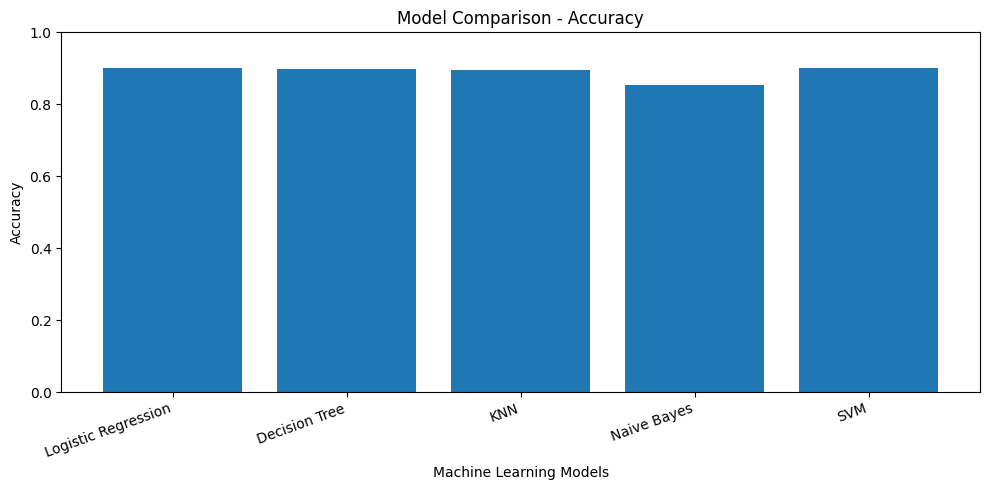

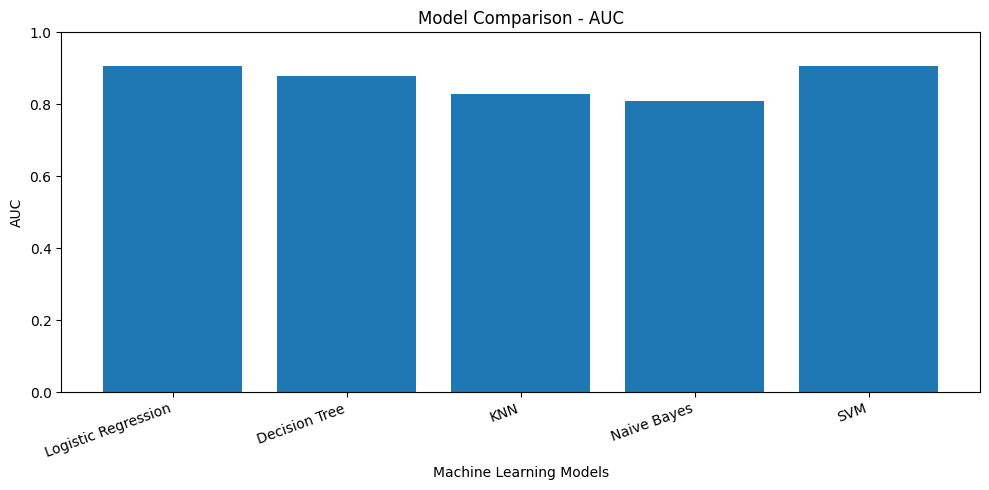

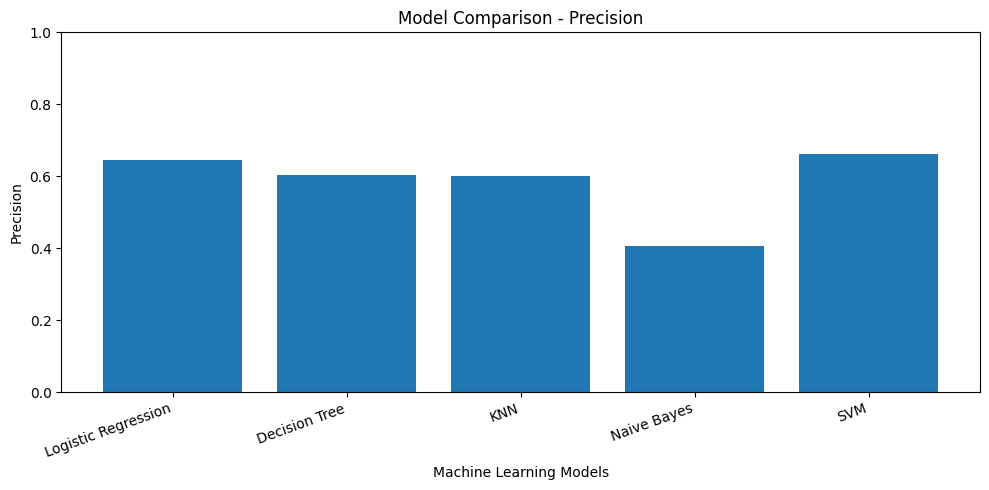

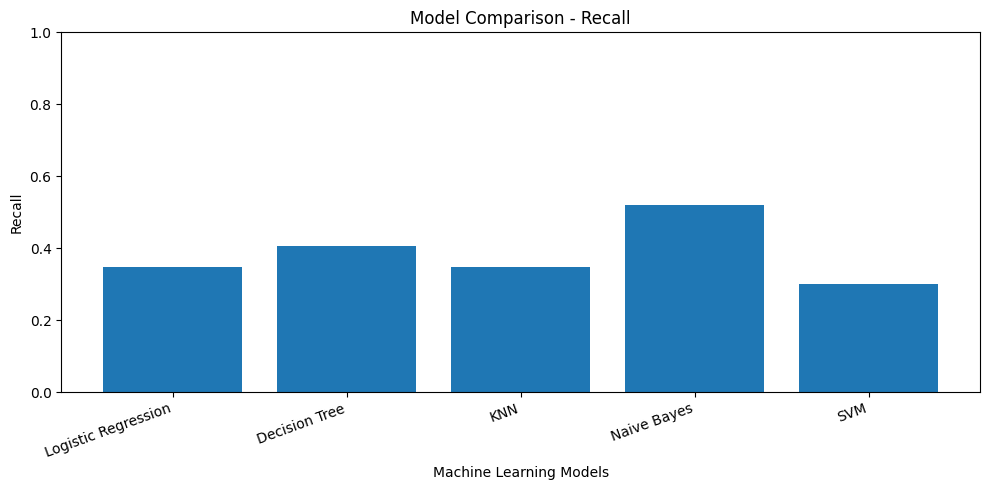

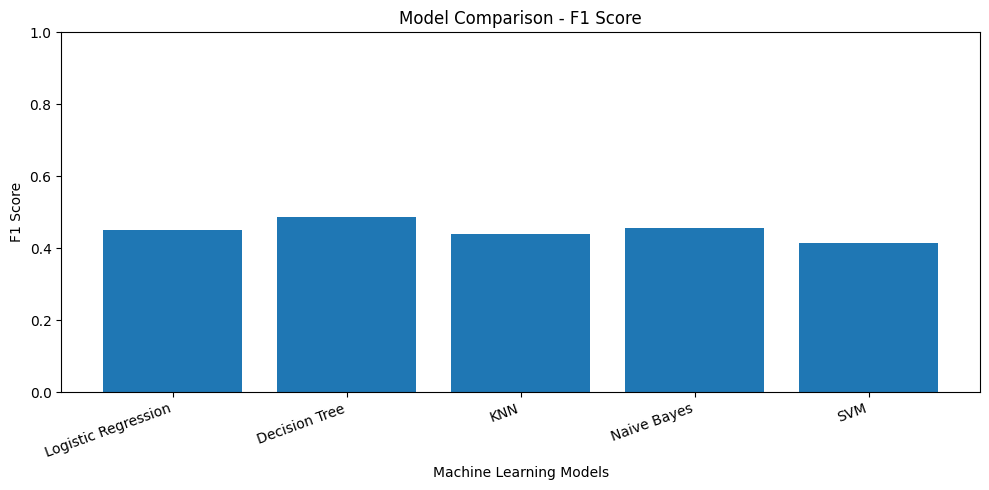

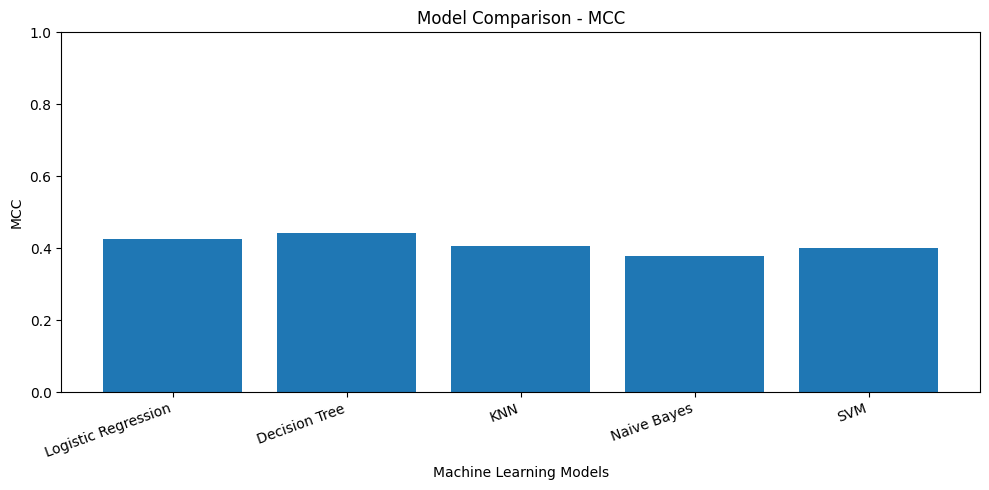

All comparison charts saved successfully!


In [46]:

import matplotlib.pyplot as plt
from pathlib import Path

Path("plots").mkdir(exist_ok=True)

metrics = [
    "Accuracy", "AUC", "Precision",
    "Recall", "F1 Score", "MCC"
]

for metric in metrics:
    plt.figure(figsize=(10, 5))

    plt.bar(
        comparison_df["Model"],
        comparison_df[metric]
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Machine Learning Models")
    plt.ylabel(metric)
    plt.xticks(rotation=20, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()

    filename = metric.lower().replace(" ", "_")
    plt.savefig(
        f"plots/{filename}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All comparison charts saved successfully!")


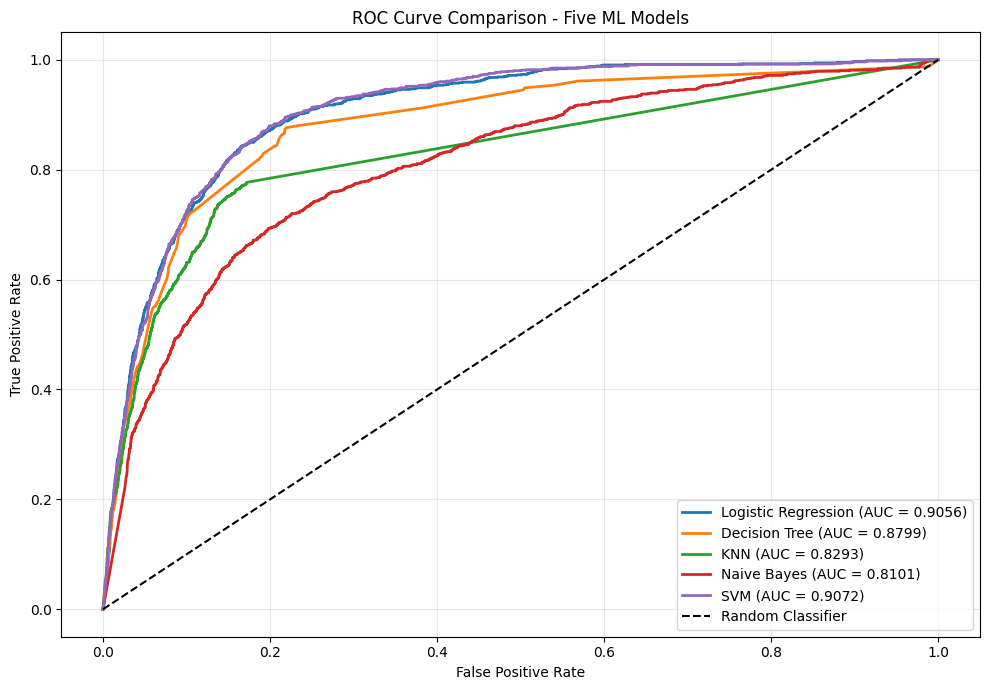

ROC curve comparison saved successfully!


In [48]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from pathlib import Path

Path("plots").mkdir(exist_ok=True)

roc_models = {
    "Logistic Regression": y_prob,
    "Decision Tree": dt_prob,
    "KNN": knn_prob,
    "Naive Bayes": nb_prob,
    "SVM": svm_scores
}

plt.figure(figsize=(10, 7))

for name, scores in roc_models.items():
    fpr, tpr, thresholds = roc_curve(y_test, scores)
    auc_value = roc_auc_score(y_test, scores)

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Five ML Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "plots/roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve comparison saved successfully!")


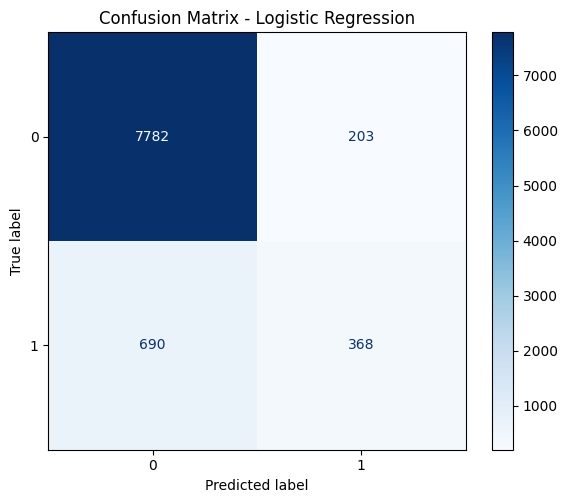

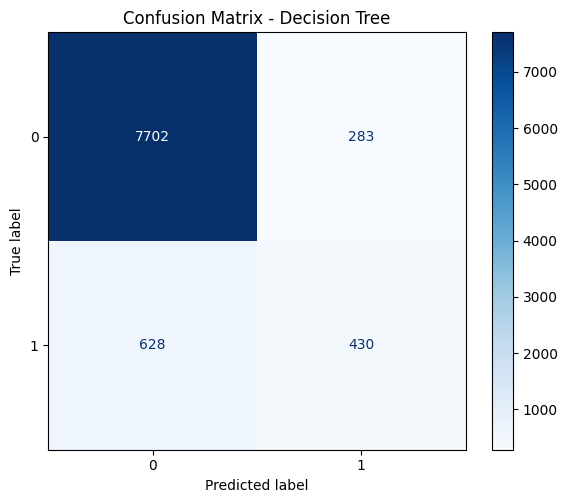

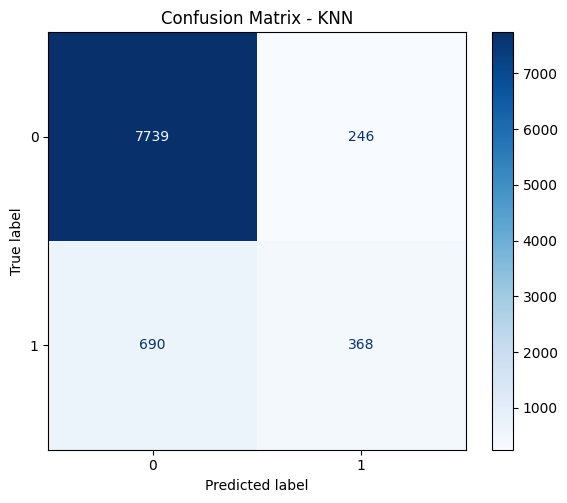

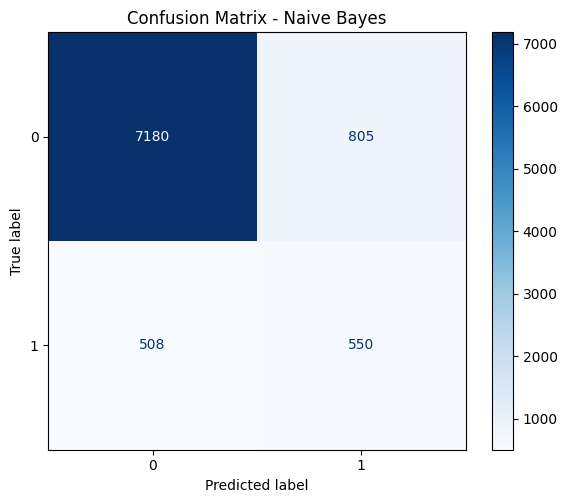

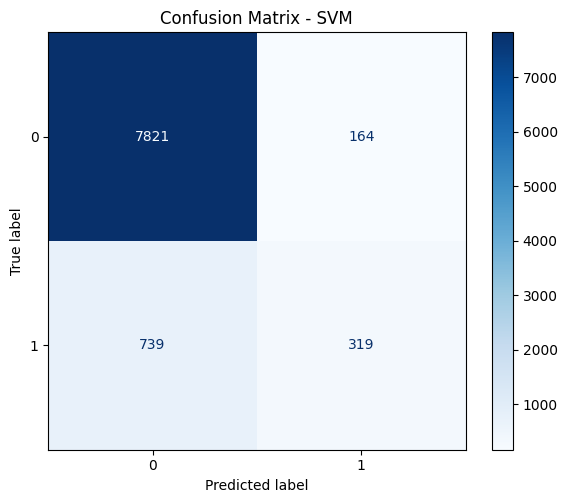

All five confusion matrices saved successfully!


In [50]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from pathlib import Path

Path("plots").mkdir(exist_ok=True)

model_predictions = {
    "Logistic Regression": y_pred,
    "Decision Tree": dt_pred,
    "KNN": knn_pred,
    "Naive Bayes": nb_pred,
    "SVM": svm_pred
}

for name, predictions in model_predictions.items():

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"Confusion Matrix - {name}")

    plt.tight_layout()

    filename = name.lower().replace(" ", "_")

    plt.savefig(
        f"plots/{filename}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All five confusion matrices saved successfully!")
